# EDA notebook: audio and speech evidence, Hazem and Ebtihal pair (Phase 1)

Project: Smart Voicemail Router. Branch: `team/audio-speech`.

Contents: 1 Snapshot. 2 Audio inventory. 3 Transcripts. 4 Dup defect. 5 Duplicates, labels, language. 6 Privacy. 7 Split. 8 Summary.

Every number below is recomputed in the cells. No transcript text, phone numbers, emails, or names appear in any output.

Note: this notebook ran when the clean set was 5,751 rows (train 4,031, validation 1,136, test 584). The clean set was later reduced to 5,096 rows (train 3,575, validation 1,003, test 518) by excluding the 655 worst transcripts (Whisper logprob below -0.30). The notebook outputs below are the record of the run as it happened. The current dataset is in final/ and dataset/ on this branch. See transcript-fix-report.md and transcript-exclusion-band2-report.md.

In [1]:
import csv
import hashlib
import json
import re
import statistics
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
import pandas as pd
from IPython.display import Image

REPO = Path("/home/hatch/workspace/ai-customer-support/smart-voicemail-router")
DATASET = Path("/home/hatch/workspace/ai-customer-support/dataset")
CSV_DIR = Path("/home/hatch/workspace/user/files")
RAR = DATASET / "dataset.rar"
EXTRACTED = DATASET / "extracted"
RAR_SHA256 = "3518fdd5edad615bf81fc25657f84c0ae476e41f9b31e09c8ea31995f9284e63"
RESULTS = {}


def read_csv(path):
    with open(path, newline="", encoding="utf-8-sig") as fh:
        return list(csv.DictReader(fh))


def dist(values):
    vals = sorted(float(v) for v in values if v not in (None, ""))
    if not vals:
        return {"count": 0}
    qs = statistics.quantiles(vals, n=10) if len(vals) >= 10 else [vals[0], vals[-1]]
    return {
        "count": len(vals),
        "mean": round(statistics.mean(vals), 4),
        "median": round(statistics.median(vals), 4),
        "min": round(vals[0], 4),
        "max": round(vals[-1], 4),
        "p10": round(qs[0], 4),
        "p90": round(qs[8] if len(qs) > 8 else qs[-1], 4),
    }


def save_bar(values, title, xlabel, ylabel, path, horizontal=False, rotation=0):
    fig = Figure()
    FigureCanvasAgg(fig)
    ax = fig.add_subplot(111)
    if horizontal:
        ax.barh(list(values.keys()), list(values.values()))
    else:
        ax.bar(list(values.keys()), list(values.values()))
        ax.tick_params(axis="x", rotation=rotation)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    return path


def save_hist(datasets, labels, title, xlabel, ylabel, path):
    fig = Figure()
    FigureCanvasAgg(fig)
    ax = fig.add_subplot(111)
    ax.hist(datasets, bins=30, label=labels, stacked=True)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    return path

## 1. Snapshot

Checks the dataset archive: size, SHA256, and the extracted file count.

In [2]:
def sha256_file(path, chunk=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        while True:
            b = fh.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


rar_size = RAR.stat().st_size
rar_hash = sha256_file(RAR)
extracted = [p for p in EXTRACTED.rglob("*") if p.is_file()]
audio_exts = {".m4a", ".mp4", ".ogg", ".mpeg", ".aac", ".mp3", ".wav", ".opus", ".ogx"}
non_audio = [p for p in extracted if p.suffix.lower() not in audio_exts]
print(f"RAR size (bytes): {rar_size}")
print(f"RAR SHA256: {rar_hash}")
print(f"SHA256 matches recorded value: {rar_hash == RAR_SHA256}")
print(f"Extracted files: {len(extracted)}")
print(f"Non-audio files inside: {len(non_audio)}")
assert rar_size == 735052270
assert rar_hash == RAR_SHA256
assert len(extracted) == 6522
assert len(non_audio) == 0
RESULTS["snapshot"] = {"rar_bytes": rar_size, "extracted_files": len(extracted)}

RAR size (bytes): 735052270
RAR SHA256: 3518fdd5edad615bf81fc25657f84c0ae476e41f9b31e09c8ea31995f9284e63
SHA256 matches recorded value: True
Extracted files: 6522
Non-audio files inside: 0


## 2. Audio inventory

The ffprobe probe ran once (script `eda/audio_inventory.py`). This cell loads the saved result and recomputes the aggregates from the per-file records. Clipping, silence, and SNR come from the inventory CSV, recomputed here; ffprobe did not re-measure them.

Duration stats:


,files,total_hours,mean_s,median_s,min_s,max_s,p10_s,p90_s
0,6522,12.63,6.972,6.208,0.4096,125.921814,4.304,10.611


Formats (by container extension):


,format,files
0,.aac,579
1,.m4a,2012
2,.mp3,472
3,.mp4,1656
4,.mpeg,723
5,.ogg,1039
6,.ogx,5
7,.opus,13
8,.wav,23


Codecs:


,codec,files
0,aac,4165
1,mp3,1177
2,opus,1157
3,pcm_s24le,23


... (5 outputs left out)

,bin,files
0,0-2s,4
1,10-15s,633
2,15-30s,157
3,2-4s,415
4,30-60s,0
5,4-6s,2532
6,6-8s,2028
7,60s+,1
8,8-10s,752


,measure,value
0,RMS level mean / median (dB),-22.6699 / -22.3
1,"Peak, maximum",1.0
2,Files with any clipping (clip_pct > 0),338 of 6522 (320 of the kept)
3,Maximum clip_pct (%),1.208
4,Silence mean / median (%),16.4879 / 15.9
5,Files with silence over 50%,18
6,SNR mean / median / min (dB),35.5305 / 34.3 / 7.3
7,Files with SNR under 10 dB,22
8,Kept files total (hours),11.685


Exclusion reasons (inventory):


,exclude_reason,files
0,(kept),6024
1,clipped,6
2,duplicate,470
3,low_snr,18
4,mostly_silence,1
5,too_long,1
6,too_short,2


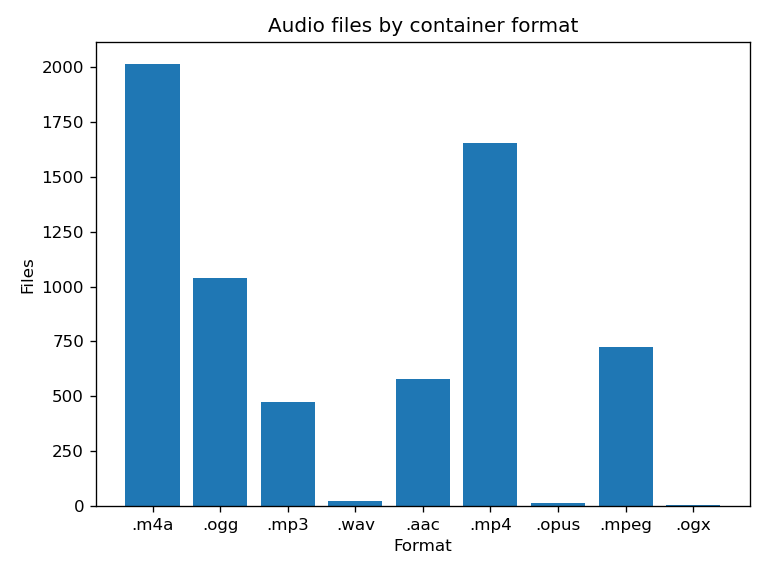

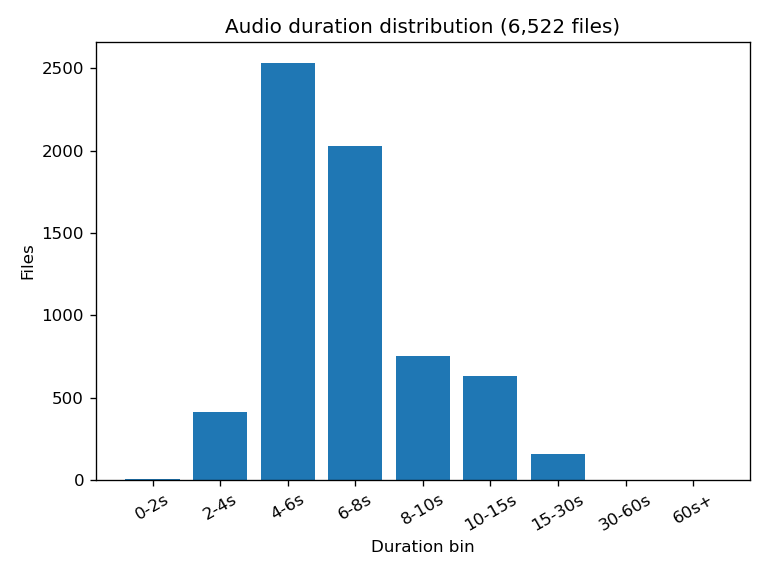

In [3]:
inv = json.loads((DATASET / "audio_inventory.json").read_text(encoding="utf-8"))
files = inv["files"]
durs = [f["duration_s"] for f in files if f["duration_s"] is not None]
qs = statistics.quantiles(sorted(durs), n=10)
dur_stats = {
    "files": len(durs),
    "total_hours": round(sum(durs) / 3600, 2),
    "mean_s": round(statistics.mean(durs), 3),
    "median_s": round(statistics.median(durs), 3),
    "min_s": min(durs),
    "max_s": max(durs),
    "p10_s": round(qs[0], 3),
    "p90_s": round(qs[8], 3),
}
formats = Counter(f["ext"] for f in files)
codecs = Counter(f["codec"] for f in files)
srs = Counter(f["sample_rate"] for f in files)
chans = Counter(f["channels"] for f in files)
unreadable = [f for f in files if f.get("error")]
bins = [(0, 2), (2, 4), (4, 6), (6, 8), (8, 10), (10, 15), (15, 30), (30, 60), (60, 10 ** 9)]
labels = ["0-2s", "2-4s", "4-6s", "6-8s", "8-10s", "10-15s", "15-30s", "30-60s", "60s+"]
hist = {lab: sum(1 for d in durs if lo <= d < hi) for (lo, hi), lab in zip(bins, labels)}
assert hist == inv["aggregate"]["duration_histogram"]
assert len(files) == 6522
assert len(unreadable) == 0
print("Duration stats:")
display(pd.DataFrame([dur_stats]))
print("Formats (by container extension):")
display(pd.DataFrame(sorted(formats.items()), columns=["format", "files"]))
print("Codecs:")
display(pd.DataFrame(sorted(codecs.items()), columns=["codec", "files"]))
print("Sample rates:")
display(pd.DataFrame(sorted(srs.items()), columns=["sample_rate_hz", "files"]))
print("Channels:")
display(pd.DataFrame(sorted(chans.items()), columns=["channels", "files"]))
print(f"Unreadable files: {len(unreadable)}")
print("Duration histogram (files per bin):")
display(pd.DataFrame(sorted(hist.items()), columns=["bin", "files"]))

inv_rows = read_csv(CSV_DIR / "inventory_clean_13_825a.csv")


def fvals(rows, col):
    return [float(r[col]) for r in rows if (r.get(col) or "") != ""]


kept = [r for r in inv_rows if not (r["exclude_reason"] or "").strip()]
clip_all = sum(1 for v in fvals(inv_rows, "clip_pct") if v > 0)
clip_kept = sum(1 for v in fvals(kept, "clip_pct") if v > 0)
sil_gt50 = sum(1 for v in fvals(inv_rows, "silence_pct") if v > 50)
snr_lt10 = sum(1 for v in fvals(inv_rows, "snr_db") if v < 10)
excl = Counter((r["exclude_reason"] or "").strip() or "(kept)" for r in inv_rows)
rms = dist(fvals(inv_rows, "rms_db"))
peak = dist(fvals(inv_rows, "peak"))
clipd = dist(fvals(inv_rows, "clip_pct"))
sild = dist(fvals(inv_rows, "silence_pct"))
snrd = dist(fvals(inv_rows, "snr_db"))
aq = pd.DataFrame([
    ["RMS level mean / median (dB)", f"{rms['mean']} / {rms['median']}"],
    ["Peak, maximum", peak["max"]],
    ["Files with any clipping (clip_pct > 0)", f"{clip_all} of {len(inv_rows)} ({clip_kept} of the kept)"],
    ["Maximum clip_pct (%)", clipd["max"]],
    ["Silence mean / median (%)", f"{sild['mean']} / {sild['median']}"],
    ["Files with silence over 50%", sil_gt50],
    ["SNR mean / median / min (dB)", f"{snrd['mean']} / {snrd['median']} / {snrd['min']}"],
    ["Files with SNR under 10 dB", snr_lt10],
    ["Kept files total (hours)", round(sum(fvals(kept, "duration_s")) / 3600, 3)],
], columns=["measure", "value"])
display(aq)
print("Exclusion reasons (inventory):")
display(pd.DataFrame(sorted(excl.items()), columns=["exclude_reason", "files"]))
p = save_bar(dict(formats), "Audio files by container format", "Format", "Files",
             REPO / "eda" / "figures" / "format_bar.png")
display(Image(filename=str(p)))
p = save_bar(hist, "Audio duration distribution (6,522 files)", "Duration bin", "Files",
             REPO / "eda" / "figures" / "duration_hist.png", rotation=30)
display(Image(filename=str(p)))
RESULTS["audio"] = {**dur_stats, "formats": dict(formats), "unreadable": 0}
RESULTS["audio_quality"] = {
    "clip_pct_gt0": clip_all, "clip_pct_gt0_kept": clip_kept,
    "silence_pct_gt50": sil_gt50, "snr_db_lt10": snr_lt10,
    "kept_hours": round(sum(fvals(kept, "duration_s")) / 3600, 3),
}

## 3. Transcripts

Recomputed live from the transcripts CSV (6,024 rows) and the 20-row evaluation file. Format v1 (10 columns) is locked; the cell checks the file carries those columns plus the `prompt` column that v1 drops.

Transcript rows: 6024
Locked v1 columns present: True
Extra columns: ['prompt']
Models: {'whisper-large-v3': 6024}
Needs review: 133 (2.2%)
Clean: 5891
Empty transcripts: 0
Error values: 0
needs_review without a reason: 0
review_reasons without the flag: 0
Review-reason token counts (a row can carry more than one):


,reason_token,rows
0,hallucination_suspect,15
1,low_confidence,121
2,prompt_leak,3
3,repetition,2
4,too_short,10


Review-reason combinations:


,combination,rows
0,hallucination_suspect,7
1,"hallucination_suspect,low_confidence",5
2,"hallucination_suspect,too_short",1
3,"hallucination_suspect,too_short,low_confidence",2
4,low_confidence,106
5,prompt_leak,1
6,"prompt_leak,low_confidence",2
7,repetition,1
8,"repetition,low_confidence",1
9,too_short,2


Prompt values: {'': 581, 'none': 5443}


,measure,mean,median,p10,p90
0,min_avg_logprob (all),-0.2019,-0.1788,-0.3278,-0.0961
1,min_avg_logprob (flagged),-0.6280,-0.5876,-0.8058,-0.5026
2,min_avg_logprob (clean),-0.1922,-0.1764,-0.3120,-0.0955
3,max_no_speech_prob (all),0.0070,0.0029,0.0003,0.0166
4,max_no_speech_prob (flagged),0.0157,0.0053,0.0004,0.0423


Text length (words): mean 15.8167, median 14.0, min 2.0, max 72.0, p10 10.0, p90 24.0
Text length (chars, mean): 81.2273
Normalized text length (words, mean): 15.8174, chars mean: 80.6376
WER eval rows: 20
whisper-large-v3 mean WER: 0.291, mean seconds per clip: 2.251
whisper-large-v3-turbo mean WER: 0.3495, mean seconds per clip: 2.479
20 rows only, and the WER is dialect-inflated, so this is a direction, not a selection proof.


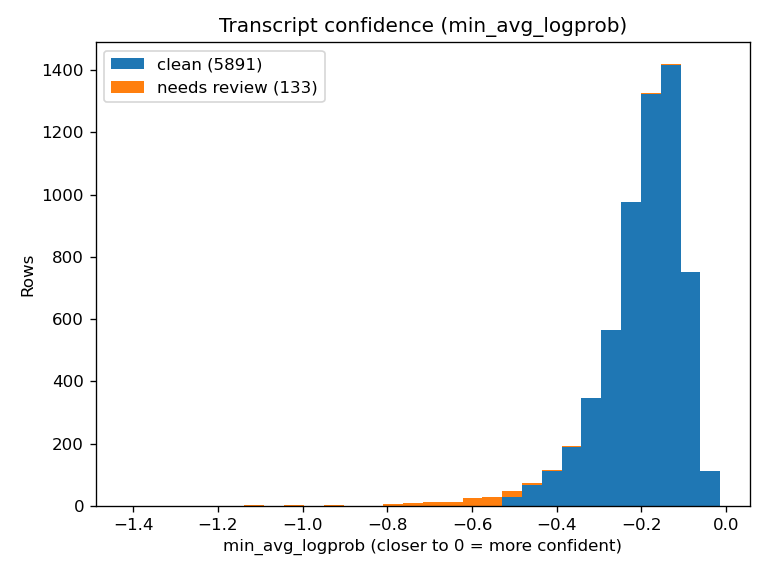

In [4]:
LOCKED_FORMAT_COLUMNS = [
    "file", "model", "text", "text_norm", "min_avg_logprob",
    "max_no_speech_prob", "needs_review", "review_reasons",
    "dup_text_size", "error",
]
t_rows = read_csv(CSV_DIR / "transcripts_flagged_14_4zfb.csv")
eval_rows = read_csv(CSV_DIR / "stt_results_12_d6z5.csv")
flagged = [r for r in t_rows if r["needs_review"].strip().lower() == "true"]
clean = [r for r in t_rows if r["needs_review"].strip().lower() != "true"]
reason_combos = Counter(r["review_reasons"].strip() for r in flagged)
reason_tokens = Counter()
for r in flagged:
    for tok in r["review_reasons"].split(","):
        tok = tok.strip()
        if tok:
            reason_tokens[tok] += 1
print(f"Transcript rows: {len(t_rows)}")
print(f"Locked v1 columns present: {all(c in t_rows[0] for c in LOCKED_FORMAT_COLUMNS)}")
print(f"Extra columns: {sorted(set(t_rows[0].keys()) - set(LOCKED_FORMAT_COLUMNS))}")
print(f"Models: {dict(Counter(r['model'] for r in t_rows))}")
print(f"Needs review: {len(flagged)} ({round(100 * len(flagged) / len(t_rows), 1)}%)")
print(f"Clean: {len(clean)}")
print(f"Empty transcripts: {sum(1 for r in t_rows if not (r['text'] or '').strip())}")
print(f"Error values: {sum(1 for r in t_rows if (r['error'] or '').strip())}")
print(f"needs_review without a reason: {sum(1 for r in flagged if not r['review_reasons'].strip())}")
print(f"review_reasons without the flag: {sum(1 for r in clean if r['review_reasons'].strip())}")
print("Review-reason token counts (a row can carry more than one):")
display(pd.DataFrame(sorted(reason_tokens.items()), columns=["reason_token", "rows"]))
print("Review-reason combinations:")
display(pd.DataFrame(sorted(reason_combos.items()), columns=["combination", "rows"]))
print(f"Prompt values: {dict(sorted(Counter((r['prompt'] or '').strip() for r in t_rows).items()))}")
log_all = dist([r["min_avg_logprob"] for r in t_rows])
log_flag = dist([r["min_avg_logprob"] for r in flagged])
log_clean = dist([r["min_avg_logprob"] for r in clean])
nsp_all = dist([r["max_no_speech_prob"] for r in t_rows])
nsp_flag = dist([r["max_no_speech_prob"] for r in flagged])
conf = pd.DataFrame([
    ["min_avg_logprob (all)", log_all["mean"], log_all["median"], log_all["p10"], log_all["p90"]],
    ["min_avg_logprob (flagged)", log_flag["mean"], log_flag["median"], log_flag["p10"], log_flag["p90"]],
    ["min_avg_logprob (clean)", log_clean["mean"], log_clean["median"], log_clean["p10"], log_clean["p90"]],
    ["max_no_speech_prob (all)", nsp_all["mean"], nsp_all["median"], nsp_all["p10"], nsp_all["p90"]],
    ["max_no_speech_prob (flagged)", nsp_flag["mean"], nsp_flag["median"], nsp_flag["p10"], nsp_flag["p90"]],
], columns=["measure", "mean", "median", "p10", "p90"])
display(conf)


def length_stats(texts):
    words = [len(t.split()) for t in texts]
    chars = [len(t) for t in texts]
    return {"words": dist(words), "chars": dist(chars)}


lt = length_stats([r["text"] or "" for r in t_rows])
ltn = length_stats([r["text_norm"] or "" for r in t_rows])
print(f"Text length (words): mean {lt['words']['mean']}, median {lt['words']['median']}, "
      f"min {lt['words']['min']}, max {lt['words']['max']}, "
      f"p10 {lt['words']['p10']}, p90 {lt['words']['p90']}")
print(f"Text length (chars, mean): {lt['chars']['mean']}")
print(f"Normalized text length (words, mean): {ltn['words']['mean']}, chars mean: {ltn['chars']['mean']}")
wer_v3 = dist([r["whisper-large-v3__wer"] for r in eval_rows])
wer_turbo = dist([r["whisper-large-v3-turbo__wer"] for r in eval_rows])
sec_v3 = dist([r["whisper-large-v3__sec"] for r in eval_rows])
sec_turbo = dist([r["whisper-large-v3-turbo__sec"] for r in eval_rows])
print(f"WER eval rows: {len(eval_rows)}")
print(f"whisper-large-v3 mean WER: {wer_v3['mean']}, mean seconds per clip: {sec_v3['mean']}")
print(f"whisper-large-v3-turbo mean WER: {wer_turbo['mean']}, mean seconds per clip: {sec_turbo['mean']}")
print("20 rows only, and the WER is dialect-inflated, so this is a direction, not a selection proof.")
flag_log = [float(r["min_avg_logprob"]) for r in flagged]
clean_log = [float(r["min_avg_logprob"]) for r in clean]
p = save_hist([clean_log, flag_log], [f"clean ({len(clean_log)})", f"needs review ({len(flag_log)})"],
              "Transcript confidence (min_avg_logprob)",
              "min_avg_logprob (closer to 0 = more confident)", "Rows",
              REPO / "eda" / "figures" / "confidence_hist.png")
display(Image(filename=str(p)))
RESULTS["transcripts"] = {
    "rows": len(t_rows), "needs_review": len(flagged), "clean": len(clean),
    "review_reason_tokens": dict(reason_tokens),
    "wer_large_v3_mean": wer_v3["mean"], "wer_turbo_mean": wer_turbo["mean"],
}

## 4. Dup defect

`dup_text_size` is recomputed from `text_norm` group sizes and compared with the stored value. The table shows file IDs and stored vs actual values only. The shared phrase is not quoted: it is a Whisper hallucination, and quoting it would put transcript text in the output.

In [5]:
group_sizes = Counter(r["text_norm"] for r in t_rows)
mismatch = pd.DataFrame([
    {"file": r["file"], "stored_dup_text_size": int(r["dup_text_size"]),
     "actual_dup_text_size": group_sizes[r["text_norm"]]}
    for r in t_rows if int(r["dup_text_size"]) != group_sizes[r["text_norm"]]
])
print("Rows where stored dup_text_size disagrees with the recount:")
display(mismatch)
print(f"Mismatched rows: {len(mismatch)}")
assert len(mismatch) == 3, "expected exactly 3 mismatched rows"
assert set(mismatch["actual_dup_text_size"]) == {3}
assert set(mismatch["stored_dup_text_size"]) == {1}
print("The fix belongs in the pipeline (recompute dup_text_size from text_norm at write time); the format stays locked.")
RESULTS["dup_defect"] = {"mismatched_rows": len(mismatch)}

Rows where stored dup_text_size disagrees with the recount:


,file,stored_dup_text_size,actual_dup_text_size
0,svr-voicemail-corpus\1015.m4a,1,3
1,svr-voicemail-corpus\WhatsApp Audio 2025-11-30 at ...,1,3
2,svr-voicemail-corpus\AUDIO-2025-11-27-17-01-39.m4a,1,3


Mismatched rows: 3
The fix belongs in the pipeline (recompute dup_text_size from text_norm at write time); the format stays locked.


## 5. Duplicates, labels, language

Text duplicates are counted by grouping on `text_norm` (group sizes only). The audio-level check uses (file size, probed duration) collisions; the note records why that proxy over-counts and why Phase 2 must use content hashes. Labels are checked, not assigned.

Distinct normalized transcripts (groups): 5872
Groups with more than one file: 108 (260 rows)
Largest group: 9 files
Group-size distribution (groups): {1: 5764, 2: 79, 3: 20, 4: 7, 5: 1, 9: 1}
Duplicate groups spanning more than one container format: 84
(size, duration) collision groups: 418, files in collisions: 953
Inventory content-based duplicate flag (is_duplicate): 470
The (size, duration) proxy over-counts; do not use it for dedup decisions.
transcripts_flagged_14_4zfb.csv: label columns present [], non-empty {}
inventory_clean_13_825a.csv: label columns present [], non-empty {}
stt_results_12_d6z5.csv: label columns present ['category_label', 'sentiment_label'], non-empty {'category_label': 0, 'sentiment_label': 0}
sample_11_laqj.csv: label columns present ['category_label', 'sentiment_label'], non-empty {'category_label': 0, 'sentiment_label': 0}
category non-empty (all files): 0
sentiment non-empty (all files): 0
No labels are finalized here; the note proposes an annotation p

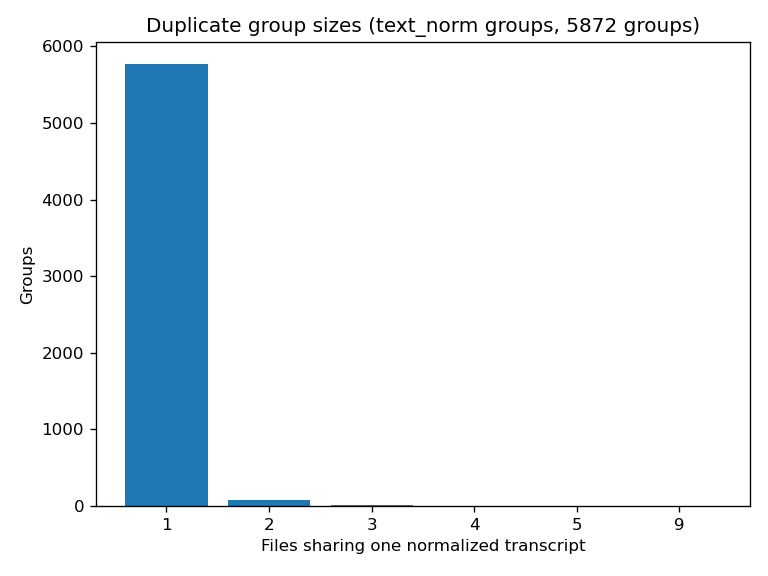

In [6]:
groups = defaultdict(list)
for r in t_rows:
    groups[r["text_norm"]].append(r["file"])
sizes = sorted((len(v) for v in groups.values()), reverse=True)
multi = [s for s in sizes if s > 1]
ext_per_group = defaultdict(set)
for r in t_rows:
    ext_per_group[r["text_norm"]].add(Path(r["file"]).suffix.lower())
multi_ext = sum(1 for v in ext_per_group.values() if len(v) > 1)
size_dist = dict(sorted(Counter(sizes).items()))
durations = {f["file"]: f["duration_s"] for f in files}
sd = Counter()
for rel, dur in durations.items():
    p = EXTRACTED / rel
    try:
        size = p.stat().st_size
    except OSError:
        continue
    sd[(size, round(dur, 3))] += 1
coll_groups = sum(1 for c in sd.values() if c > 1)
coll_files = sum(c for c in sd.values() if c > 1)
inv_dup_flag = sum(1 for r in inv_rows if (r["is_duplicate"] or "").strip().lower() == "true")
print(f"Distinct normalized transcripts (groups): {len(groups)}")
print(f"Groups with more than one file: {len(multi)} ({sum(multi)} rows)")
print(f"Largest group: {sizes[0]} files")
print(f"Group-size distribution (groups): {size_dist}")
print(f"Duplicate groups spanning more than one container format: {multi_ext}")
print(f"(size, duration) collision groups: {coll_groups}, files in collisions: {coll_files}")
print(f"Inventory content-based duplicate flag (is_duplicate): {inv_dup_flag}")
print("The (size, duration) proxy over-counts; do not use it for dedup decisions.")
LABEL_COLUMNS = ["category_label", "sentiment_label"]
sample_rows = read_csv(CSV_DIR / "sample_11_laqj.csv")
cat_total = 0
sent_total = 0
for name, rows in [
    ("transcripts_flagged_14_4zfb.csv", t_rows),
    ("inventory_clean_13_825a.csv", inv_rows),
    ("stt_results_12_d6z5.csv", eval_rows),
    ("sample_11_laqj.csv", sample_rows),
]:
    present = [c for c in LABEL_COLUMNS if rows and c in rows[0]]
    counts = {c: sum(1 for r in rows if (r.get(c) or "").strip()) for c in present}
    cat_total += counts.get("category_label", 0)
    sent_total += counts.get("sentiment_label", 0)
    print(f"{name}: label columns present {present}, non-empty {counts}")
print(f"category non-empty (all files): {cat_total}")
print(f"sentiment non-empty (all files): {sent_total}")
print("No labels are finalized here; the note proposes an annotation protocol for team approval.")
LATIN_TOKEN_RE = re.compile(r"[A-Za-z]+")
latin_tokens = Counter()
rows_with_latin = 0
for r in t_rows:
    toks = [t.lower() for t in LATIN_TOKEN_RE.findall(r["text"] or "")]
    if toks:
        rows_with_latin += 1
        latin_tokens.update(toks)
print(f"Rows containing Latin-script tokens: {rows_with_latin} of {len(t_rows)}")
print(f"Rows in pure Arabic script: {len(t_rows) - rows_with_latin}")
print(f"Top Latin tokens (counts only): {latin_tokens.most_common(12)}")
p = save_bar({str(k): v for k, v in size_dist.items()},
             f"Duplicate group sizes (text_norm groups, {len(groups)} groups)",
             "Files sharing one normalized transcript", "Groups",
             REPO / "eda" / "figures" / "dup_size.png")
display(Image(filename=str(p)))
RESULTS["duplicates"] = {
    "text_norm_groups": len(groups), "groups_gt1": len(multi),
    "rows_in_dup_groups": sum(multi), "largest_group": sizes[0],
    "multi_format_groups": multi_ext,
    "size_duration_collision_groups": coll_groups,
    "size_duration_collision_files": coll_files,
    "inventory_is_duplicate_flag": inv_dup_flag,
}
RESULTS["labels"] = {"category_non_empty": cat_total, "sentiment_non_empty": sent_total}
RESULTS["language"] = {"rows_with_latin_tokens": rows_with_latin,
                       "rows_pure_arabic": len(t_rows) - rows_with_latin}

## 6. Privacy

Pattern counts only, over transcript text and normalized text. No matched strings are stored and no examples are shown.

In [7]:
PHONE_RE = re.compile(r"01[0-9]{9}")
INTL_PHONE_RE = re.compile(r"(?:\+20|0020)\s?1[0-9]{9}")
EMAIL_RE = re.compile(r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}")
LONG_DIGITS_RE = re.compile(r"\d{10,}")
phone = email = long_digits = intl = 0
for r in t_rows:
    text = (r["text"] or "") + " " + (r["text_norm"] or "")
    if PHONE_RE.search(text):
        phone += 1
    if INTL_PHONE_RE.search(text):
        intl += 1
    if EMAIL_RE.search(text):
        email += 1
    if LONG_DIGITS_RE.search(text):
        long_digits += 1
priv = pd.DataFrame([
    ["Egyptian mobile pattern", phone],
    ["International (+20) phone pattern", intl],
    ["Email pattern", email],
    ["Digit runs of 10 or more", long_digits],
], columns=["pattern", "rows"])
display(priv)
assert phone == 0 and intl == 0 and email == 0 and long_digits == 0
print("No phone numbers or email addresses appear in the transcripts by these patterns.")
print("Person names cannot be detected reliably from transcripts alone, so no name count is attempted.")
RESULTS["privacy"] = {
    "rows_scanned": len(t_rows), "phone_like_rows": phone,
    "intl_phone_like_rows": intl, "email_like_rows": email,
    "long_digit_run_rows": long_digits,
}

,pattern,rows
0,Egyptian mobile pattern,0
1,International (+20) phone pattern,0
2,Email pattern,0
3,Digit runs of 10 or more,0


No phone numbers or email addresses appear in the transcripts by these patterns.
Person names cannot be detected reliably from transcripts alone, so no name count is attempted.


## 7. Split

Group-aware 70/20/10 split over the 6,024 transcribed rows. Whole `text_norm` groups stay on one side. This replaces the 80/10/10 proposal in the EDA note, because the user standard is 70/20/10.

In [8]:
TARGET_SHARES = {"train": 0.7, "val": 0.2, "test": 0.1}
norm = lambda f: f.replace("\\", "/")
row_durations = sorted(durations[norm(r["file"])] for r in t_rows if norm(r["file"]) in durations)
q1, q2, q3 = statistics.quantiles(row_durations, n=4)


def quartile(d):
    if d <= q1:
        return "Q1"
    if d <= q2:
        return "Q2"
    if d <= q3:
        return "Q3"
    return "Q4"


groups2 = defaultdict(list)
for r in t_rows:
    groups2[r["text_norm"]].append(r)
group_info = []
for text_norm, members in groups2.items():
    durs_m = [durations[norm(m["file"])] for m in members if norm(m["file"]) in durations]
    mean_dur = statistics.mean(durs_m) if durs_m else 0.0
    ext = Counter(Path(m["file"]).suffix.lower() for m in members).most_common(1)[0][0]
    group_info.append({"text_norm": text_norm, "size": len(members),
                       "mean_duration": mean_dur, "stratum": (quartile(mean_dur), ext)})
group_info.sort(key=lambda g: (g["stratum"], -g["size"], g["text_norm"]))
total = len(t_rows)
targets = {k: round(v * total) for k, v in TARGET_SHARES.items()}
targets["train"] += total - sum(targets.values())
counts = Counter()
assignment = {}
for g in group_info:
    split = max(TARGET_SHARES, key=lambda s: (targets[s] - counts[s]) / targets[s])
    counts[split] += g["size"]
    for m in groups2[g["text_norm"]]:
        assignment[m["file"]] = split
group_sides = defaultdict(set)
for r in t_rows:
    group_sides[r["text_norm"]].add(assignment[r["file"]])
leaked = sum(1 for sides in group_sides.values() if len(sides) > 1)
per_split = {}
for split in ("train", "val", "test"):
    members = [r for r in t_rows if assignment[r["file"]] == split]
    durs_s = [durations[norm(r["file"])] for r in members if norm(r["file"]) in durations]
    per_split[split] = {
        "rows": len(members),
        "needs_review": sum(1 for r in members if r["needs_review"].strip().lower() == "true"),
        "duration_mean_s": round(statistics.mean(durs_s), 3),
    }
print(f"Split sizes: train {counts['train']}, val {counts['val']}, test {counts['test']}")
print(f"Duration quartiles (s): Q1 {round(q1, 3)}, Q2 {round(q2, 3)}, Q3 {round(q3, 3)}")
print(f"Duplicate groups leaking across sides: {leaked}")
display(pd.DataFrame([
    [s, per_split[s]["rows"], per_split[s]["needs_review"], per_split[s]["duration_mean_s"]]
    for s in ("train", "val", "test")
], columns=["split", "rows", "needs_review", "duration_mean_s"]))
assert counts["train"] + counts["val"] + counts["test"] == total
assert leaked == 0
for s, share in TARGET_SHARES.items():
    assert abs(counts[s] / total - share) < 0.02, s
(DATASET / "split_assignment.json").write_text(
    json.dumps({"assignment": assignment}, indent=2, ensure_ascii=False), encoding="utf-8")
print("Proposal saved to dataset/split_assignment.json (70/20/10).")
print("Limitation: no speaker IDs exist, so this split is not speaker-aware.")
RESULTS["split"] = {"train": counts["train"], "val": counts["val"], "test": counts["test"],
                    "leaked_duplicate_groups": leaked}

Split sizes: train 4217, val 1205, test 602
Duration quartiles (s): Q1 5.12, Q2 6.223, Q3 7.874
Duplicate groups leaking across sides: 0


,split,rows,needs_review,duration_mean_s
0,train,4217,92,6.984
1,val,1205,25,7.028
2,test,602,16,6.897


Proposal saved to dataset/split_assignment.json (70/20/10).
Limitation: no speaker IDs exist, so this split is not speaker-aware.


## 8. Summary

Headline numbers, recomputed in the cells above. Open items for the team meeting are listed in the note, section 10: rights and consent, split approval, the dup fix confirmation, the annotation protocol, and the preprocessing scope.

In [9]:
print(json.dumps(RESULTS, indent=2, ensure_ascii=False))

{
  "snapshot": {
    "rar_bytes": 735052270,
    "extracted_files": 6522
  },
  "audio": {
    "files": 6522,
    "total_hours": 12.63,
    "mean_s": 6.972,
    "median_s": 6.208,
    "min_s": 0.4096,
    "max_s": 125.921814,
    "p10_s": 4.304,
    "p90_s": 10.611,
    "formats": {
      ".m4a": 2012,
      ".ogg": 1039,
      ".mp3": 472,
      ".wav": 23,
      ".aac": 579,
      ".mp4": 1656,
      ".opus": 13,
      ".mpeg": 723,
      ".ogx": 5
    },
    "unreadable": 0
  },
  "audio_quality": {
    "clip_pct_gt0": 338,
    "clip_pct_gt0_kept": 320,
    "silence_pct_gt50": 18,
    "snr_db_lt10": 22,
    "kept_hours": 11.685
  },
  "transcripts": {
    "rows": 6024,
    "needs_review": 133,
    "clean": 5891,
    "review_reason_tokens": {
      "low_confidence": 121,
      "prompt_leak": 3,
      "hallucination_suspect": 15,
      "too_short": 10,
      "repetition": 2
    },
    "wer_large_v3_mean": 0.291,
    "wer_turbo_mean": 0.3495
  },
  "dup_defect": {
    "mismatched_rows